# Week 6 · Topic 4 — Apply, Lambda and Finishing Up

**Box we are building: STORE + PROCESS, the whole job**

A `lambda` is a `def` you don't bother naming, for a one-line function you are
only going to use once — usually right inside `.apply()`.

> **Already know this?** Skip to the *Topic 4 Challenge*.

---
## 1. `.apply()` runs a function on every value in a column

Start with a normal function, the way Week 3 taught it.

In [ ]:
import pandas as pd

servers = pd.read_csv("servers.csv")
servers["percent"] = (servers["used"] / servers["total"]) * 100

def classify(percent):
    if percent >= 100:
        return "OVER LIMIT"
    elif percent >= 90:
        return "WARNING"
    else:
        return "OK"

servers["status"] = servers["percent"].apply(classify)
print(servers)

  hostname  used  total region     percent      status
0   srv-01    50     60   east   83.333333          OK
1   srv-02    30     55   west   54.545455          OK
2   srv-03    55     30  north  183.333333  OVER LIMIT
3   srv-04    10     98  south   10.204082          OK
4   srv-05    16     56   east   28.571429          OK
5   srv-06    90    101   west   89.108911          OK


### Your turn
Write your own single-argument function and `.apply()` it to the `used` column.

In [4]:
def above30(value):
    if value >=30:
        return "It's Above 30"
    else:
        return "It's not above 30"
servers["above30"] = servers["used"].apply(above30)
print(servers)

  hostname  used  total region     percent      status            above30
0   srv-01    50     60   east   83.333333          OK      It's Above 30
1   srv-02    30     55   west   54.545455          OK      It's Above 30
2   srv-03    55     30  north  183.333333  OVER LIMIT      It's Above 30
3   srv-04    10     98  south   10.204082          OK  It's not above 30
4   srv-05    16     56   east   28.571429          OK  It's not above 30
5   srv-06    90    101   west   89.108911          OK      It's Above 30


---
## 2. `lambda` - the same idea, written inline

`lambda parameters: expression` — that IS the whole function. Only one
expression allowed — no `if`/`elif`/`else` statements, no loops.

In [ ]:
double = lambda x: x * 2
print(double(21))     # 42 - same as def double(x): return x * 2

```
def classify(p):                    lambda p: (
    if p >= 100:                        "OVER LIMIT" if p >= 100
        return "OVER LIMIT"             else "WARNING" if p >= 90
    elif p >= 90:                       else "OK"
        return "WARNING"             )
    else:
        return "OK"

same logic, same result - a block of statements vs one expression
```

### Your turn
Write `classify` as a lambda with a chained conditional, and check it gives the same result as the `def` version for every row.

In [5]:
classify = lambda p: (
    "OVER LIMIT" if p>=100
    else "WARNING" if p>=90
    else "OK"
)
print(classify(87))

OK


---
## 3. `.apply()` with a lambda, and `sort_values(key=...)`

lambda earns its place exactly here — a function small enough to write inline,
used exactly once, right where it is needed.

In [ ]:
servers["status"] = servers["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
print(servers.sort_values("hostname", key=lambda col: col.str.lower()))

### Your turn
Use `.apply()` with a lambda to add a column `region_upper` — the `region` column, in capitals.

In [6]:
servers["region_upper"] = servers["region"].apply(lambda r: r.upper())
print(servers)

  hostname  used  total region     percent      status            above30  \
0   srv-01    50     60   east   83.333333          OK      It's Above 30   
1   srv-02    30     55   west   54.545455          OK      It's Above 30   
2   srv-03    55     30  north  183.333333  OVER LIMIT      It's Above 30   
3   srv-04    10     98  south   10.204082          OK  It's not above 30   
4   srv-05    16     56   east   28.571429          OK  It's not above 30   
5   srv-06    90    101   west   89.108911          OK      It's Above 30   

  region_upper  
0         EAST  
1         WEST  
2        NORTH  
3        SOUTH  
4         EAST  
5         WEST  


---
## 4. Summarising, saving, and a first chart

`describe()` for a quick overview, `.to_csv()` to save, and one chart — straight
off a DataFrame. In a notebook, calling `.plot()` shows the chart inline.

Matplotlib is building the font cache; this may take a moment.


            used       total     percent
count   6.000000    6.000000    6.000000
mean   41.833333   66.666667   74.849424
std    29.600113   27.565679   61.281306
min    10.000000   30.000000   10.204082
25%    19.500000   55.250000   35.064935
50%    40.000000   58.000000   68.939394
75%    53.750000   88.500000   87.665017
max    90.000000  101.000000  183.333333


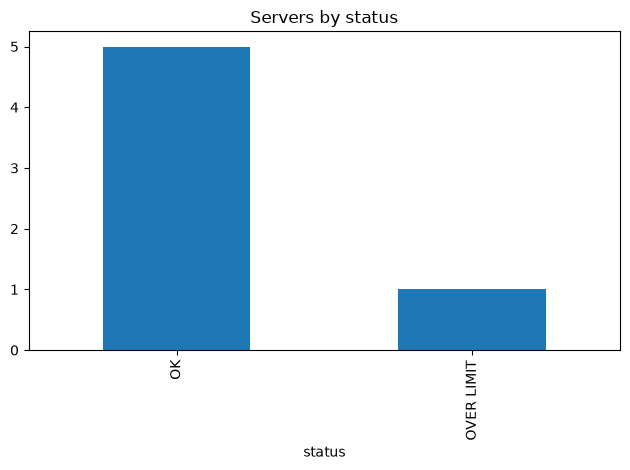

In [8]:
import matplotlib.pyplot as plt

print(servers.describe())

servers.to_csv("servers_report.csv", index=False)

servers["status"].value_counts().plot(kind="bar", title="Servers by status")
plt.tight_layout()
plt.show()

### Your turn
Make a bar chart of servers per region instead of per status.

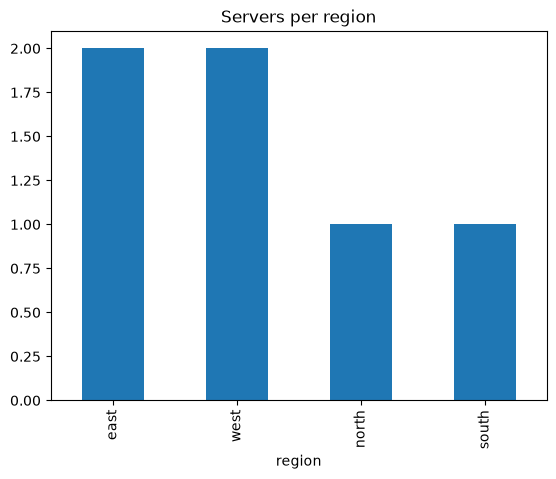

In [13]:
servers["region"].value_counts().plot(kind = "bar",title = "Servers per region")
plt.show()

---
## Topic 4 Challenge

Load `servers.csv`, add `percent` and `status` (via `.apply()` with a lambda),
save the result to a new CSV, and produce one bar chart of the status counts.

  hostname  used  total region     percent     status
0   srv-01    50     60   east   83.333333         OK
1   srv-02    30     55   west   54.545455         OK
2   srv-03    55     30  north  183.333333  OVERLIMIT
3   srv-04    10     98  south   10.204082         OK
4   srv-05    16     56   east   28.571429         OK
5   srv-06    90    101   west   89.108911         OK


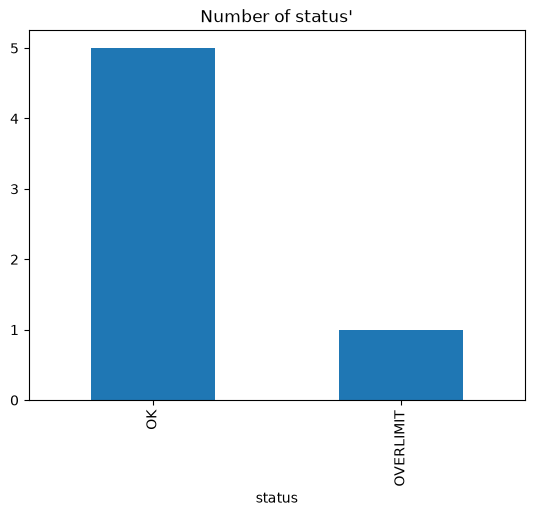

In [ ]:
Server = pd.read_csv("servers.csv")
Server["percent"] = Server["used"]/Server["total"] *100
Server["status"] = Server["percent"].apply(
    lambda p: "OVERLIMIT" if p >=100 else "WARNING" if p>=90 else "OK")
print(Server)
Server.to_csv("Serversave1.csv",index = False)
Server["status"].value_counts().plot(kind = "bar",title = "Number of status'")
plt.show()

---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | `df["clean_text"] = df["text"].apply(lambda t: t.strip().lower())` |
| **Cyber Security** | `df["flag"] = df["failed"].apply(lambda n: n >= 3)` |
| **IT** | `df.sort_values("hostname", key=lambda c: c.str.lower())` |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| a lambda with an `if` statement (not an expression) | `SyntaxError` | lambda only allows one expression — use chained `if/else`, or write a `def` |
| reusing the same lambda logic in three places | works, but repeats the logic three times | that is the sign you wanted a named function, not a lambda |
| forgetting `.apply()` and just writing `column.classify()` | `AttributeError` | `.apply(function)` runs your function on every value — the function itself is not a method on the column |
| calling `.plot()` in a plain script and seeing nothing | no chart appears | add `plt.show()` (script) — a notebook shows it automatically |

## Go deeper

`examples/01_apply_and_lambda.py` — apply, lambda syntax, chained conditionals, sort key
`examples/02_summarizing_saving_and_charting.py` — describe, to_csv, a first chart

---
## Recap

| You can now | Using |
|---|---|
| apply a function to a whole column | `column.apply(function)` |
| write a small inline function | `lambda x: expression` |
| choose lambda vs a named function | one-line, used once → lambda; reused or complex → `def` |
| get a quick overview | `.describe()` |
| save a result | `.to_csv(path, index=False)` |
| chart straight from a DataFrame | `.plot(kind=...)` |

**You now have all of CW1's toolkit.** Your mini-project this week closes it out.